In [ ]:
# CELL 1: Setup and load the raw files
# What we're doing: import libraries and read the 3 files already uploaded to Colab.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# File names exactly as they appear in the Colab file panel
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_sub = pd.read_csv("sample_submission.csv")  # used at the end for the submission format

# Quick check: should be (8523, 12), (5681, 11)
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_sub.shape)

# First rows and column types
print(train.head())
print(train.dtypes)

Train shape: (8523, 12)
Test shape: (5681, 11)
Sample submission shape: (5681, 3)
  Item_Identifier  Item_Weight Item_Fat_Content  Item_Visibility  \
0           FDA15         9.30          Low Fat         0.016047   
1           DRC01         5.92          Regular         0.019278   
2           FDN15        17.50          Low Fat         0.016760   
3           FDX07        19.20          Regular         0.000000   
4           NCD19         8.93          Low Fat         0.000000   

               Item_Type  Item_MRP Outlet_Identifier  \
0                  Dairy  249.8092            OUT049   
1            Soft Drinks   48.2692            OUT018   
2                   Meat  141.6180            OUT049   
3  Fruits and Vegetables  182.0950            OUT010   
4              Household   53.8614            OUT013   

   Outlet_Establishment_Year Outlet_Size Outlet_Location_Type  \
0                       1999      Medium               Tier 1   
1                       2009      Medium  

In [ ]:
# CELL 2: Step 1 - Combine train and test into one table
# What we're doing: stack both tables so every cleaning rule is applied identically to both. The 'source' column lets us split them back later.
# EDA STAGE: 1. LOAD (combine train and test)

train["source"] = "train"
test["source"] = "test"

# Test has no sales column, so concat fills it with blanks (NaN)
data = pd.concat([train, test], ignore_index=True)

# Checks: 8523 + 5681 = 14204 rows, 13 columns (12 original + source)
print("Combined shape:", data.shape)
print(data["source"].value_counts())
print("Sales blanks:", data["Item_Outlet_Sales"].isnull().sum())

Combined shape: (14204, 13)
source
train    8523
test     5681
Name: count, dtype: int64
Sales blanks: 5681


In [ ]:
# CELL 3: Step 2.1 - Column types
# What we're doing: split columns by type, then check on the only discrete column (Year): unique values, distribution, relation to sales.
# EDA STAGE: 2. UNIVARIATE ANALYSIS (2.1 column types)

# Split by data type
discrete = data.select_dtypes(include="int64").columns.tolist()
continuous = data.select_dtypes(include="float64").columns.tolist()
categorical = data.select_dtypes(include="object").columns.tolist()

print("Discrete (int64):", discrete)
print("Continuous (float64):", continuous)
print("Categorical (object):", categorical)

Discrete (int64): ['Outlet_Establishment_Year']
Continuous (float64): ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Item_Outlet_Sales']
Categorical (object): ['Item_Identifier', 'Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type', 'source']


Unique years: 9
[np.int64(1985), np.int64(1987), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2002), np.int64(2004), np.int64(2007), np.int64(2009)]
Correlation of Year with sales: -0.04913497044082089


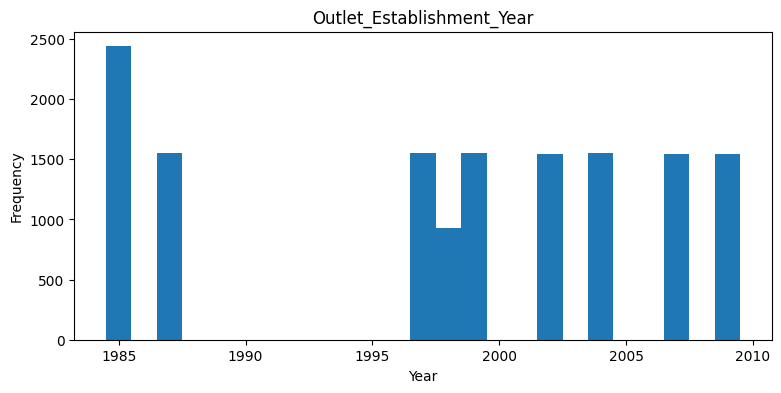

In [ ]:
# EDA STAGE: 2. UNIVARIATE ANALYSIS (2.1 column types)
# CELL 4: Step 2.1 - Is Outlet_Establishment_Year really a number?
# What we're doing: Year is stored as int64, so by the class rule it counts as discrete numeric. Before we accept that, we check 3 things:
#   1) How many unique values it has (few values = more like a label than a number)
#   2) Its correlation with sales (does a later year mean more or less sales?)
#   3) Its histogram (a bell shape = a real numeric spread; spikes with gaps = groups)
# Result decides if Year stays numeric or becomes categorical (done in Cell 5).

year = data["Outlet_Establishment_Year"]
train_rows = data[data["source"] == "train"]

# 1) Unique values
print("Unique years:", year.nunique())
print(sorted(year.unique()))

# 2) Relationship with the target (train rows only, test has no sales)
print("Correlation of Year with sales:", train_rows["Outlet_Establishment_Year"].corr(train_rows["Item_Outlet_Sales"]))

# 3) Histogram, one bar per year (bins are 1 year wide, centred on each year)
year.plot.hist(bins=np.arange(1984.5, 2010.5, 1), title="Outlet_Establishment_Year", figsize=(9, 4))
plt.xlabel("Year")
plt.show()

                    mean   skew  nulls  zeros
Item_Weight       12.793  0.101   2439      0
Item_Visibility    0.066  1.195      0    879
Item_MRP         141.005  0.131      0      0


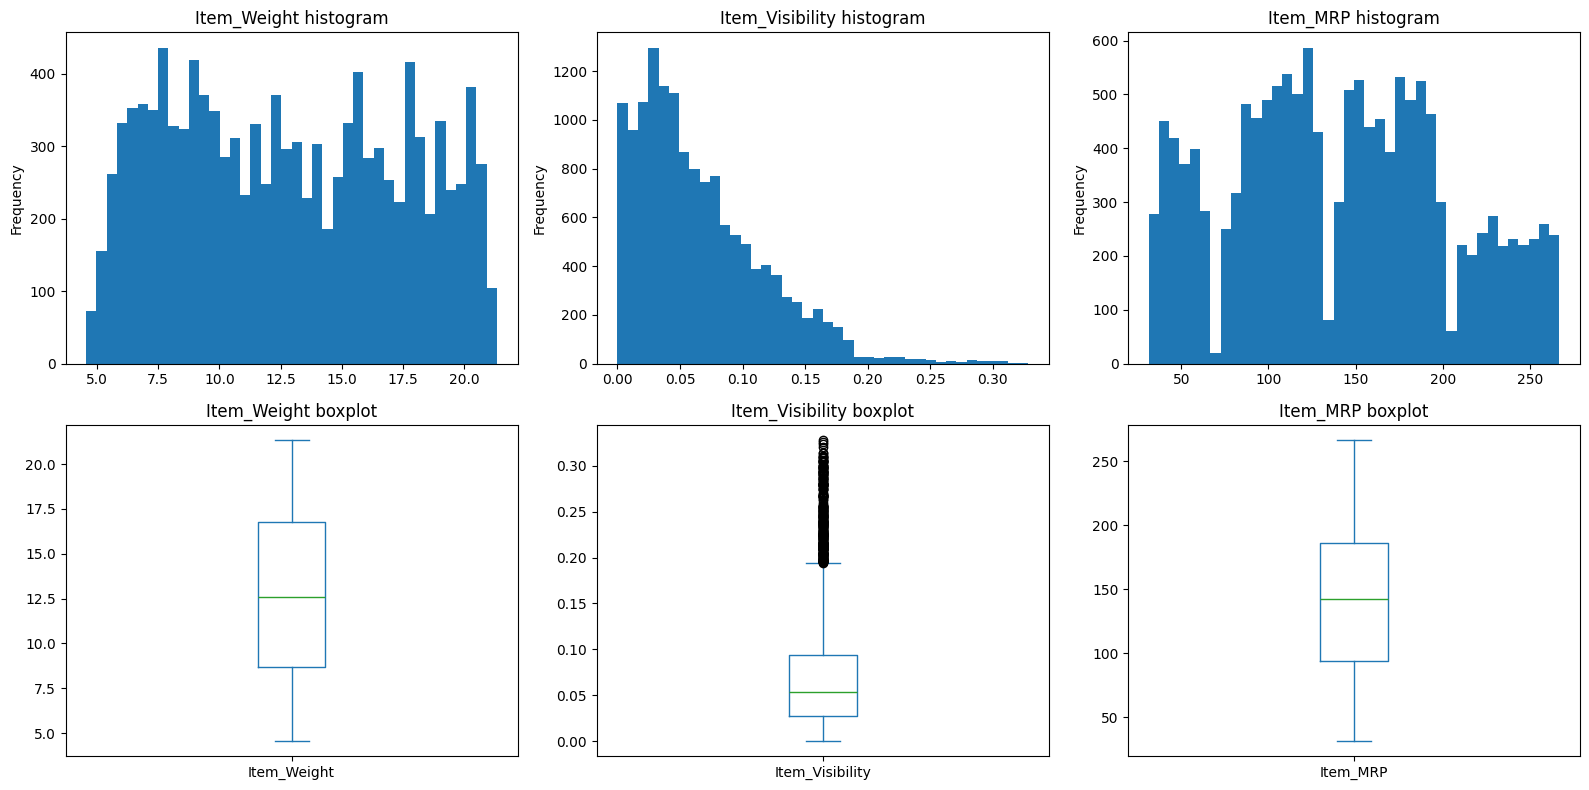

In [ ]:
# EDA STAGE: 2. UNIVARIATE ANALYSIS (2.2 numeric description)
# CELL 5: Step 2.2 - Numeric description
# What we're doing:
#  a) Year failed the normality and target checks, so convert it to categorical (text).
#  b) Describe the 3 continuous predictors: mean, skew, nulls, zeros.
#  c) Plot a histogram (shape) and a boxplot (outliers) for each.

# a) Year -> categorical
data["Outlet_Establishment_Year"] = data["Outlet_Establishment_Year"].astype(str)

# b) Numeric summary table
num_cols = ["Item_Weight", "Item_Visibility", "Item_MRP"]
summary = pd.DataFrame({"mean": data[num_cols].mean(), "skew": data[num_cols].skew(), "nulls": data[num_cols].isnull().sum(), "zeros": (data[num_cols] == 0).sum(),})
print(summary.round(3))

# c) Graphs: top row = histograms, bottom row = boxplots
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, col in enumerate(num_cols):
    data[col].plot.hist(bins=40, ax=axes[0, i], title=col + " histogram")
    data[col].plot.box(ax=axes[1, i], title=col + " boxplot")
plt.tight_layout()
plt.show()

Correlation with Item_Outlet_Sales:
Item_Weight        0.014
Item_Visibility   -0.129
Item_MRP           0.568
dtype: float64


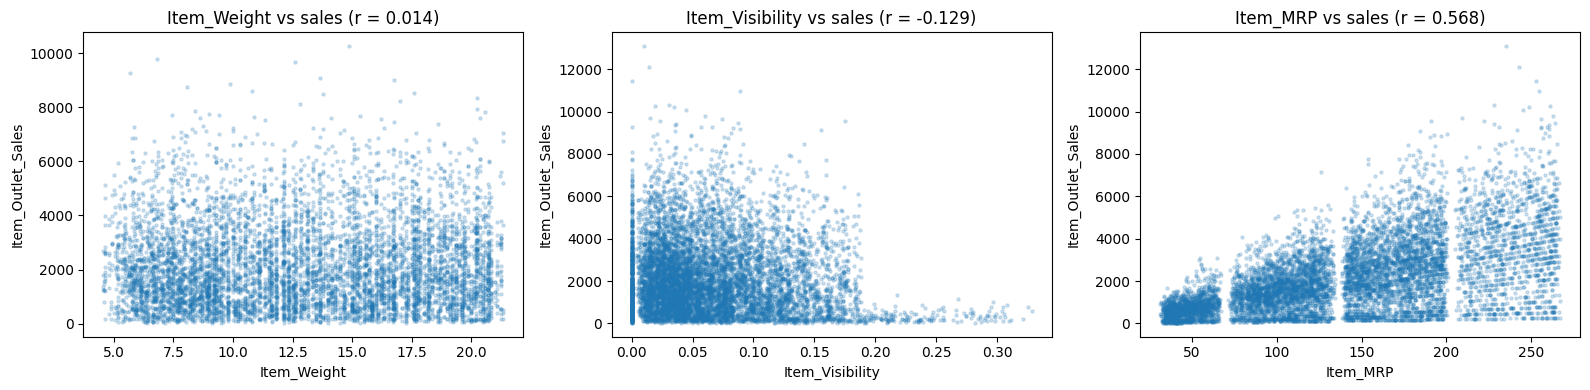

In [ ]:
# EDA STAGE: 2. UNIVARIATE ANALYSIS (2.2b prerequisite 4: related to the target)
# CELL 6: Correlation of each numeric column with the target (TV = Item_Outlet_Sales)
# What we're doing: check whether each numeric column moves with sales.
# Correlation runs from -1 to +1. Near 0 = no linear relation.
# Train rows only, because test has no sales. Missing weights are skipped automatically.

train_rows = data[data["source"] == "train"]
num_cols = ["Item_Weight", "Item_Visibility", "Item_MRP"]

# Correlation numbers
corr = train_rows[num_cols].corrwith(train_rows["Item_Outlet_Sales"])
print("Correlation with Item_Outlet_Sales:")
print(corr.round(3))

# Scatter plots: each column vs sales
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(num_cols):
    train_rows.plot.scatter(x=col, y="Item_Outlet_Sales", alpha=0.2, s=5, ax=axes[i],title=f"{col} vs sales (r = {corr[col]:.3f})")
plt.tight_layout()
plt.show()

Mean: 2181.29
Median: 1794.33
Min: 33.29 | Max: 13086.96
Skew: 1.178
Nulls: 0
Zeros: 0
Negatives: 0


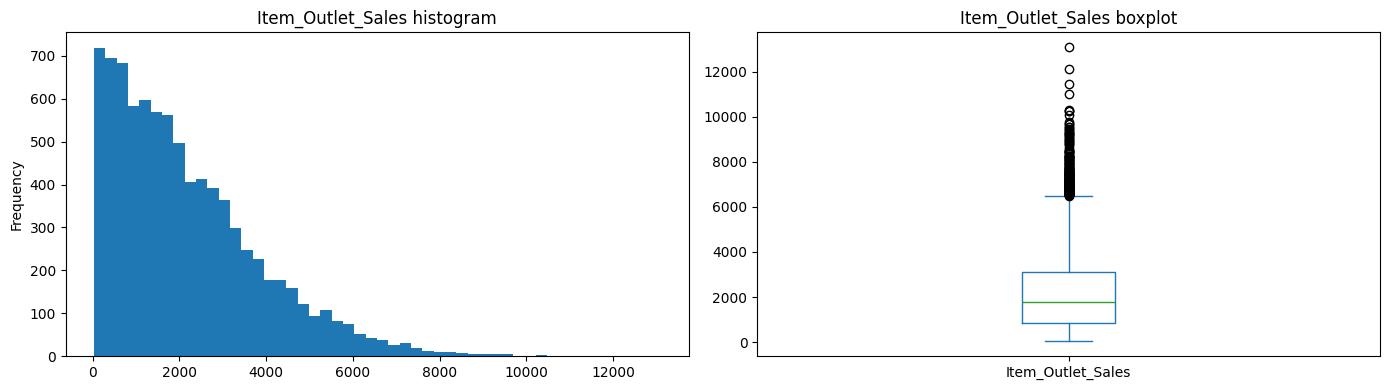

In [ ]:
# EDA STAGE: 2. UNIVARIATE ANALYSIS (2.3 target variable)
# CELL 7: Step 2.3 - Describe the target, Item_Outlet_Sales
# What we're doing: check the target on train rows only (test has no sales).
# Look for nulls, zeros, negatives, skew, and outliers.

sales = data.loc[data["source"] == "train", "Item_Outlet_Sales"]

print("Mean:", round(sales.mean(), 2))
print("Median:", round(sales.median(), 2))
print("Min:", round(sales.min(), 2), "| Max:", round(sales.max(), 2))
print("Skew:", round(sales.skew(), 3))
print("Nulls:", sales.isnull().sum())
print("Zeros:", (sales == 0).sum())
print("Negatives:", (sales < 0).sum())

# Graphs: histogram (distribution and skew) and boxplot (outliers)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sales.plot.hist(bins=50, ax=axes[0], title="Item_Outlet_Sales histogram")
sales.plot.box(ax=axes[1], title="Item_Outlet_Sales boxplot")
plt.tight_layout()
plt.show()

In [ ]:
# EDA STAGE: 2. UNIVARIATE ANALYSIS (2.4 categorical columns)
# CELL 8: Step 2.4 - Scan for blanks, then count the values in each categorical column

# Blanks per column (sales blanks = 5,681 test rows, expected)
print("Blanks per column:")
print(data.isnull().sum())

# Number of products (Item_Identifier is an ID, not a feature)
print("Unique products:", data["Item_Identifier"].nunique())

# Counts per category, blanks included. Look for messy spellings.
cat_cols = ["Item_Fat_Content", "Item_Type", "Outlet_Identifier", "Outlet_Establishment_Year", "Outlet_Size", "Outlet_Location_Type", "Outlet_Type"]

for col in cat_cols:
    print("\n", data[col].value_counts(dropna=False))


Blanks per column:
Item_Identifier                 0
Item_Weight                  2439
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  4016
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales            5681
source                          0
dtype: int64
Unique products: 1559

 Item_Fat_Content
Low Fat    8485
Regular    4824
LF          522
reg         195
low fat     178
Name: count, dtype: int64

 Item_Type
Fruits and Vegetables    2013
Snack Foods              1989
Household                1548
Frozen Foods             1426
Dairy                    1136
Baking Goods             1086
Canned                   1084
Health and Hygiene        858
Meat                      736
Soft Drinks               726
Breads                    416
Hard Drinks               362
Others 

In [ ]:
# EDA STAGE: 2. UNIVARIATE ANALYSIS (2.5 fix categorical spellings)
# CELL 9: Step 2.5 - Merge the 5 fat-content spellings into 2 values

data["Item_Fat_Content"] = data["Item_Fat_Content"].replace({"LF": "Low Fat", "low fat": "Low Fat", "reg": "Regular",})

print(data["Item_Fat_Content"].value_counts())

Item_Fat_Content
Low Fat    9185
Regular    5019
Name: count, dtype: int64


         column  skew needs_log_check  zeros_left_out  skew_after_log
    Item_Weight  0.10              no               0             NaN
Item_Visibility  1.20             yes             879           -0.43
       Item_MRP  0.13              no               0             NaN


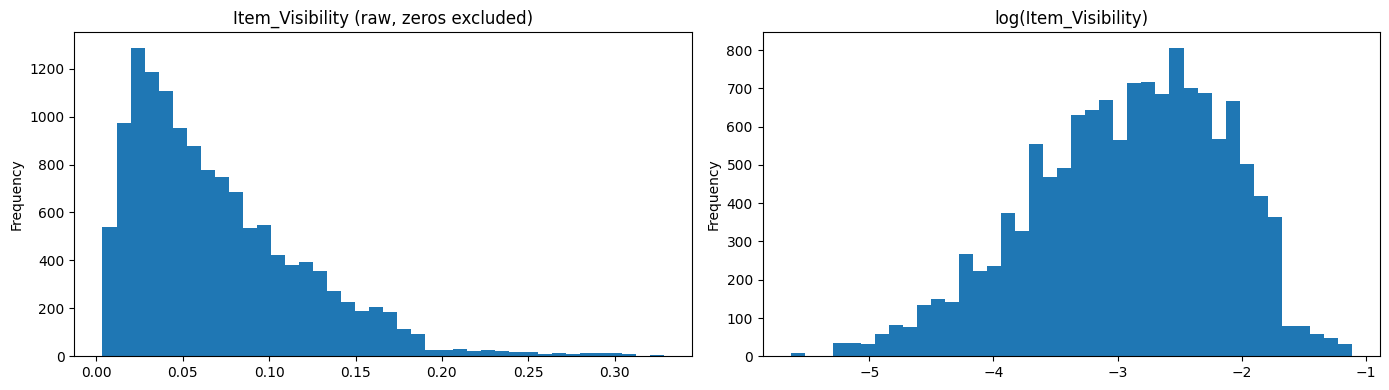

In [ ]:
# EDA STAGE: 2. UNIVARIATE ANALYSIS (2.6 log check for skewed columns)
# CELL 10: Step 2.6 - Would a log fix the skewed predictor columns?
# What we're doing: only columns with |skew| > 1 get a log check.
# A log can't take 0, so Visibility's zeros are left out here (they're fixed in Step 5).
# Only predictors are checked; the target (Item_Outlet_Sales) is kept as it is.

check = {"Item_Weight": data["Item_Weight"].dropna(), "Item_Visibility": data["Item_Visibility"], "Item_MRP": data["Item_MRP"]}

rows = []
for col, s in check.items():
    skew = s.skew()
    if abs(skew) > 1:
        pos = s[s > 0]
        rows.append([col, round(skew, 2), "yes", int((s == 0).sum()), round(np.log(pos).skew(), 2)])
    else:
        rows.append([col, round(skew, 2), "no", 0, None])

log_table = pd.DataFrame(rows, columns=["column", "skew", "needs_log_check", "zeros_left_out", "skew_after_log"])
print(log_table.to_string(index=False))

# Graph for the skewed column: raw histogram vs log histogram
vis_pos = data.loc[data["Item_Visibility"] > 0, "Item_Visibility"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
vis_pos.plot.hist(bins=40, ax=axes[0], title="Item_Visibility (raw, zeros excluded)")
np.log(vis_pos).plot.hist(bins=40, ax=axes[1], title="log(Item_Visibility)")
plt.tight_layout()
plt.show()

Standard deviation of sales: 1706
Outlet_Type: (gap 3354 | gap / SD (1706) = 1.97)
                     mean  count
Outlet_Type                     
Grocery Store       340.0   1083
Supermarket Type2  1995.0    928
Supermarket Type1  2316.0   5577
Supermarket Type3  3694.0    935
Outlet_Identifier: (gap 3355 | gap / SD (1706) = 1.97)
                     mean  count
Outlet_Identifier               
OUT010              339.0    555
OUT019              340.0    528
OUT018             1995.0    928
OUT045             2192.0    929
OUT046             2278.0    930
OUT013             2299.0    932
OUT017             2341.0    926
OUT049             2348.0    930
OUT035             2439.0    930
OUT027             3694.0    935
Outlet_Establishment_Year: (gap 2144 | gap / SD (1706) = 1.26)
                             mean  count
Outlet_Establishment_Year               
1998                        339.0    555
2009                       1995.0    928
2002                       2192.0    929


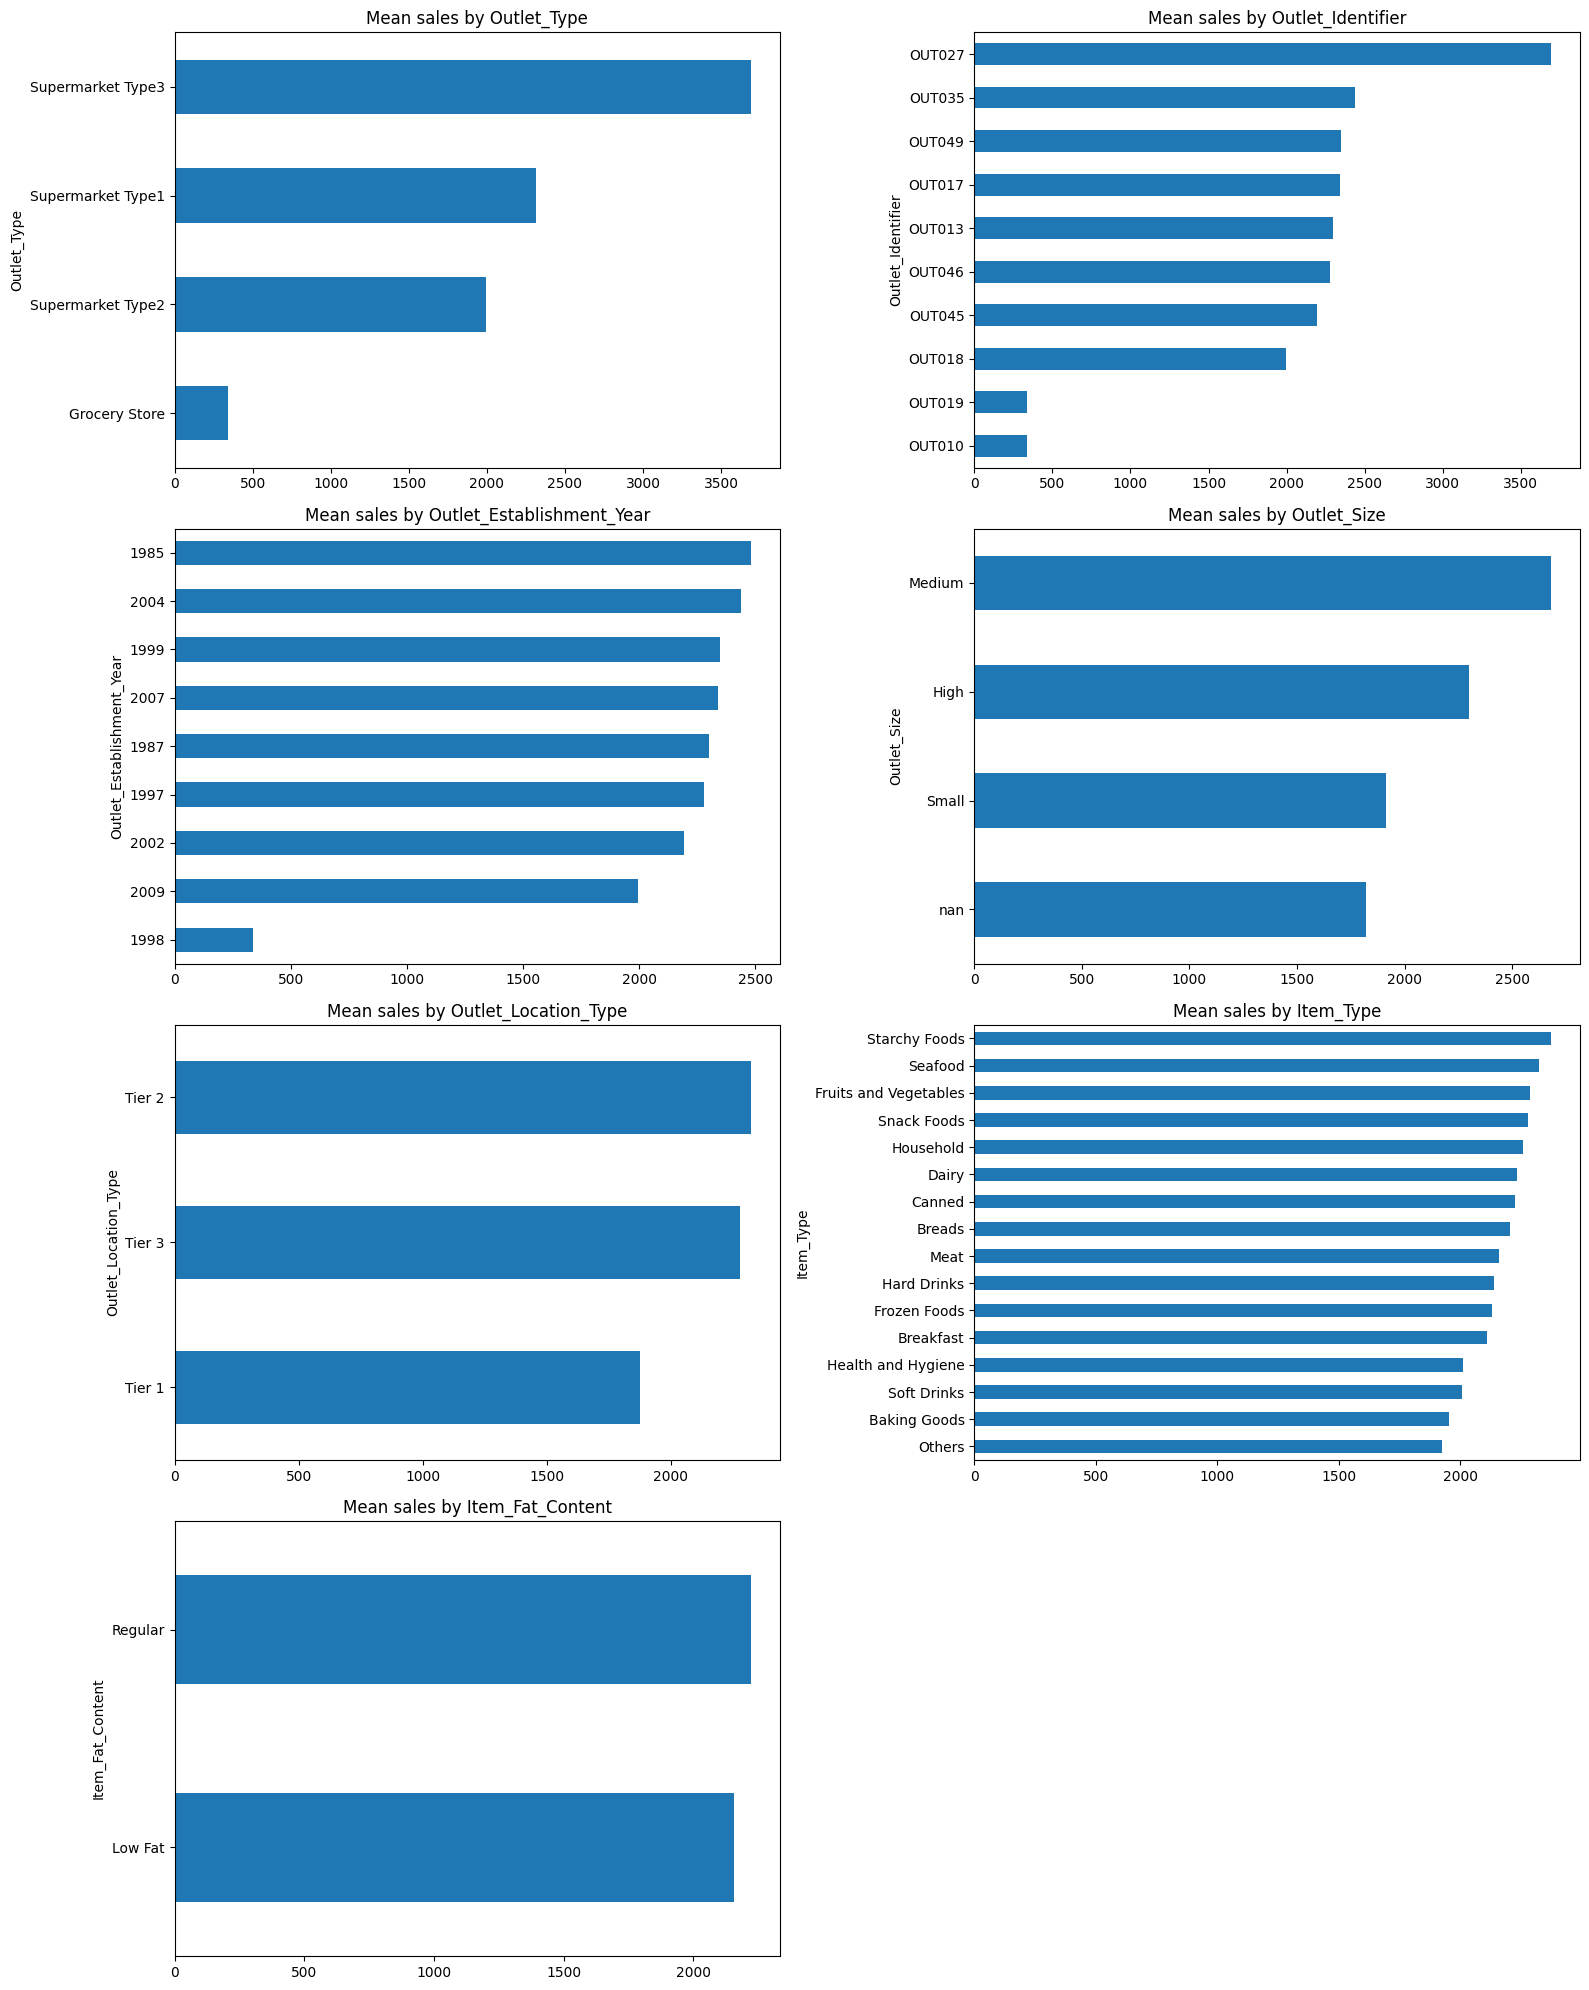

In [ ]:
# EDA STAGE: 3. BIVARIATE ANALYSIS (3.1 categorical vs target)
# CELL 11: Step 3.1 - Average sales per category, one column at a time
# What we're doing: group train rows by each categorical column and compare mean sales.
# How to tell a big gap from a small one: compare the gap with the normal row-to-row variation in sales (standard deviation):
# gap / SD about 1 or more = category moves sales more than normal variation -> big
# gap / SD a small fraction = category effect is lost in normal variation  -> small
# Year is included here because Step 2.1 converted it to categorical.

train_rows = data[data["source"] == "train"]
sd = train_rows["Item_Outlet_Sales"].std()
print(f"Standard deviation of sales: {sd:.0f}")

cat_cols = ["Outlet_Type", "Outlet_Identifier", "Outlet_Establishment_Year", "Outlet_Size", "Outlet_Location_Type", "Item_Type", "Item_Fat_Content"]

summary = []
for col in cat_cols:
    m = (train_rows.groupby(col, dropna=False)["Item_Outlet_Sales"].agg(["mean", "count"]).sort_values("mean"))
    gap = m["mean"].max() - m["mean"].min()
    summary.append([col, round(gap), round(gap / sd, 2)])
    print(f"{col}: (gap {gap:.0f} | gap / SD ({sd:.0f}) = {gap / sd:.2f})")
    print(m.round(0))

print("Summary (biggest gap first):")
print(pd.DataFrame(summary, columns=["column", "gap", "gap_to_std"]).sort_values("gap_to_std", ascending=False).to_string(index=False))

# Graphs: one bar chart per column, bars = mean sales per category
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    (train_rows.groupby(col, dropna=False)["Item_Outlet_Sales"].mean().sort_values().plot.barh(ax=axes[i], title=f"Mean sales by {col}"))
axes[-1].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# EDA STAGE: 3. BIVARIATE ANALYSIS (3.2 store profile)
# CELL 12: Step 3.2 - One row per store: type, tier, size, year, mean sales
# What we're doing: see which stores are missing Outlet_Size and which labelled stores they look most like. This sets up the fill in Step 4.
# Also shows why Size and Year looked strong in 3.1 (they follow the store).

train_rows = data[data["source"] == "train"]

store_profile = (train_rows.groupby("Outlet_Identifier").agg(Outlet_Type=("Outlet_Type", "first"),Tier=("Outlet_Location_Type", "first"), Size=("Outlet_Size", "first"), Year=("Outlet_Establishment_Year", "first"), mean_sales=("Item_Outlet_Sales", "mean"), rows=("Item_Outlet_Sales", "count")).sort_values(["Outlet_Type", "Tier"]))

store_profile["Size"] = store_profile["Size"].fillna("MISSING")
print(store_profile.round(0))

print("Stores with missing size:",store_profile[store_profile["Size"] == "MISSING"].index.tolist())

                         Outlet_Type    Tier     Size  Year  mean_sales  rows
Outlet_Identifier                                                            
OUT019                 Grocery Store  Tier 1    Small  1985       340.0   528
OUT010                 Grocery Store  Tier 3  MISSING  1998       339.0   555
OUT046             Supermarket Type1  Tier 1    Small  1997      2278.0   930
OUT049             Supermarket Type1  Tier 1   Medium  1999      2348.0   930
OUT017             Supermarket Type1  Tier 2  MISSING  2007      2341.0   926
OUT035             Supermarket Type1  Tier 2    Small  2004      2439.0   930
OUT045             Supermarket Type1  Tier 2  MISSING  2002      2192.0   929
OUT013             Supermarket Type1  Tier 3     High  1987      2299.0   932
OUT018             Supermarket Type2  Tier 3   Medium  2009      1995.0   928
OUT027             Supermarket Type3  Tier 3   Medium  1985      3694.0   935
Stores with missing size: ['OUT010', 'OUT017', 'OUT045']


In [ ]:
# EDA STAGE: 4. MISSING VALUES
# CELL 13: Step 4 - Fill Item_Weight and Outlet_Size
# a) Item_Weight: a product weighs the same in every store, so fill each blank with the same product's weight from its other rows (train + test).
# b) Outlet_Size: the 3 unsized stores all match a Small store (Cell 12):
#    OUT010 -> OUT019 (only other grocery), OUT017/OUT045 -> OUT035 (only labelled Tier 2 Type1).

print("Blanks before:")
print(data[["Item_Weight", "Outlet_Size"]].isnull().sum())

# Check first: does each product really have one weight? (should print 1)
print("\nMax different weights per product:",
      data.groupby("Item_Identifier")["Item_Weight"].nunique().max())

# a) Item_Weight
data["Item_Weight"] = data["Item_Weight"].fillna(
    data.groupby("Item_Identifier")["Item_Weight"].transform("mean"))

# b) Outlet_Size
size_fill = {"OUT010": "Small", "OUT017": "Small", "OUT045": "Small"}
data["Outlet_Size"] = data["Outlet_Size"].fillna(data["Outlet_Identifier"].map(size_fill))

print("\nBlanks after:")
print(data[["Item_Weight", "Outlet_Size"]].isnull().sum())
print("\nOutlet_Size counts:")
print(data["Outlet_Size"].value_counts())

Blanks before:
Item_Weight    2439
Outlet_Size    4016
dtype: int64

Max different weights per product: 1

Blanks after:
Item_Weight    0
Outlet_Size    0
dtype: int64

Outlet_Size counts:
Outlet_Size
Small     7996
Medium    4655
High      1553
Name: count, dtype: int64


Outliers (raw):
Item_Weight     :    0   (fence -3.35 to 28.81)
Item_Visibility :  261   (fence -0.073 to 0.195)
Item_MRP        :    0   (fence -43.753 to 323.621)

Item_Visibility zeros: 879 (invalid value, not an outlier)

Item_Visibility raw -> after log: 249 ->52


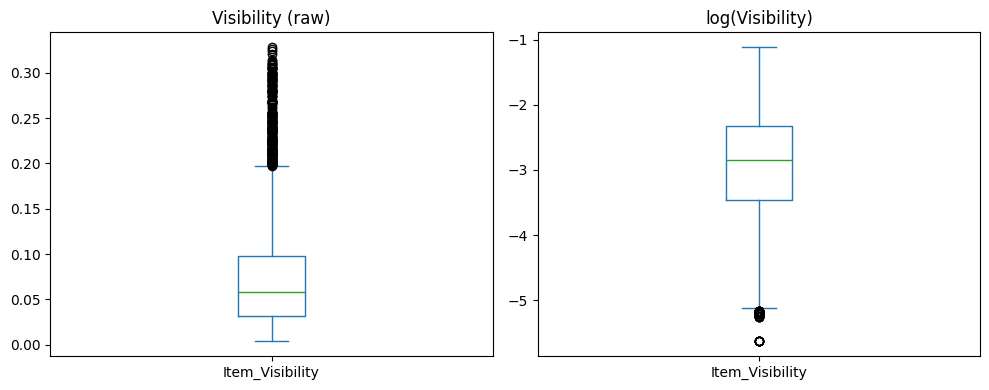

In [ ]:
# EDA STAGE: 5. OUTLIERS (5.1 detection)
# CELL 14: Step 5.1 - Count outliers with the IQR rule, then re-check after log
# IQR rule: a value is an outlier if it is below Q1 - 1.5*IQR or above Q3 + 1.5*IQR.
# Re-check after log: if the outliers disappear, they were caused by skew. If they survive, they are genuine extreme values.
# Predictors only. Item_Outlet_Sales is the target variable, so it is not treated.

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((s < low) | (s > high)).sum()), round(low, 3), round(high, 3)

# a) Raw counts
print("Outliers (raw):")
for col in ["Item_Weight", "Item_Visibility", "Item_MRP"]:
    n, low, high = iqr_outliers(data[col])
    print(f"{col:<16}: {n:4d}   (fence {low} to {high})")

print("\nItem_Visibility zeros:", (data["Item_Visibility"] == 0).sum(), "(invalid value, not an outlier)")

# b) Visibility re-check after log (zeros left out, a log can't take 0)
vis_pos = data.loc[data["Item_Visibility"] > 0, "Item_Visibility"]
print(f"\nItem_Visibility raw -> after log: {iqr_outliers(vis_pos)[0]} ->{iqr_outliers(np.log(vis_pos))[0]}")

# c) Boxplots: raw vs log
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
vis_pos.plot.box(ax=axes[0], title="Visibility (raw)")
np.log(vis_pos).plot.box(ax=axes[1], title="log(Visibility)")
plt.tight_layout()
plt.show()

Zeros before: 879
Zeros after: 0
Blanks after: 0
New minimum: 0.0036
Skew after fix: 1.234


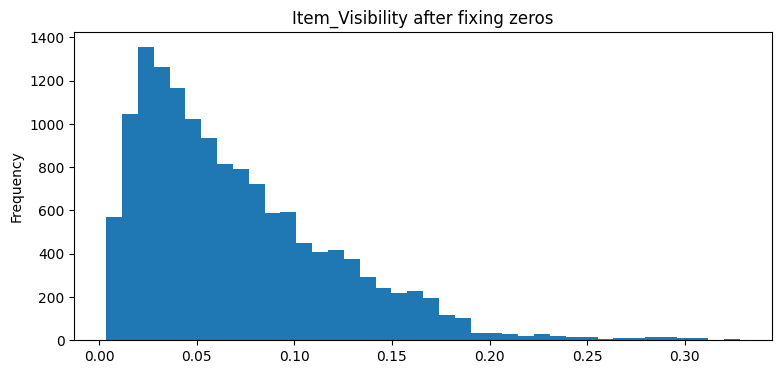

In [ ]:
# EDA STAGE: 5. OUTLIERS (5.2 treatment)
# CELL 15: Step 5.2 - Fix the 879 visibility zeros
# A product on the shelf can't take up 0 space, so 0 = missing value in disguise.
# Treat zeros as blanks, then fill with the same product's average visibility across its other stores (train + test).
# Decisions from Cell 14 (no code needed):
#   - Visibility high tail: mostly skew (249 -> 52 after log). Not capped; log version made in Step 6.
#   - Item_Outlet_Sales: target variable, not treated.
#   - Weight, MRP: no outliers.

print("Zeros before:", (data["Item_Visibility"] == 0).sum())

data["Item_Visibility"] = data["Item_Visibility"].replace(0, np.nan)
data["Item_Visibility"] = data["Item_Visibility"].fillna(data.groupby("Item_Identifier")["Item_Visibility"].transform("mean"))

print("Zeros after:", (data["Item_Visibility"] == 0).sum())
print("Blanks after:", data["Item_Visibility"].isnull().sum())
print("New minimum:", round(data["Item_Visibility"].min(), 4))
print("Skew after fix:", round(data["Item_Visibility"].skew(), 3))

data["Item_Visibility"].plot.hist(bins=40, title="Item_Visibility after fixing zeros", figsize=(9, 4))
plt.show()

In [ ]:
# EDA STAGE: 6. VARIABLE CREATION
# CELL 16: Step 6 - Create 5 new columns from the existing ones

# 6.1 Item_Category: first 2 letters of the ID give a broad category
data["Item_Category"] = data["Item_Identifier"].str[:2].map(
    {"FD": "Food", "DR": "Drinks", "NC": "Non-Consumable"})

# 6.1b Cleaning that needs 6.1 (not a new column): fat content makes no sense for soap or household goods, so non-consumables get their own label
data.loc[data["Item_Category"] == "Non-Consumable", "Item_Fat_Content"] = "Non-Edible"

# 6.2 Outlet_Age: data collected in 2013 (Year is text since Cell 5, so convert back)
data["Outlet_Age"] = 2013 - data["Outlet_Establishment_Year"].astype(int)

# 6.3 Item_Visibility_Ratio: shelf space in this store vs the product's average(>1 = this store gives it more space than usual, <1 = less)
data["Item_Visibility_Ratio"] = data["Item_Visibility"] / data.groupby("Item_Identifier")["Item_Visibility"].transform("mean")

# 6.4 Item_MRP_Band: the 4 price clusters seen in the MRP histogram (gaps near 69, 136, 203)
data["Item_MRP_Band"] = pd.cut(data["Item_MRP"], bins=[0, 69, 136, 203, np.inf],labels=["Low", "Medium", "High", "Very High"])

# 6.5 Item_Visibility_log: Step 2.6 showed the log makes visibility nearly symmetric
data["Item_Visibility_log"] = np.log(data["Item_Visibility"])

# Checks that the columns were built correctly
print(data["Item_Category"].value_counts(), "\n")
print(data["Item_Fat_Content"].value_counts(), "\n")
print("Outlet_Age range:", data["Outlet_Age"].min(), "to", data["Outlet_Age"].max())
print("Visibility_Ratio mean (should be 1):", round(data["Item_Visibility_Ratio"].mean(), 4))
print("\n", data["Item_MRP_Band"].value_counts().sort_index())
print("\nVisibility_log skew:", round(data["Item_Visibility_log"].skew(), 3))
print("Shape:", data.shape)

# Are the new columns related to sales? (train only)
train_rows = data[data["source"] == "train"]
sd = train_rows["Item_Outlet_Sales"].std()

# a) Categorical -> mean sales per category, gap / SD (same rule as Cell 11)
for col in ["Item_Category", "Item_MRP_Band", "Item_Fat_Content"]:
    m = train_rows.groupby(col, observed=True)["Item_Outlet_Sales"].mean()
    gap = m.max() - m.min()
    print(f"\nMean sales by {col}  (gap {gap:.0f} | gap / SD = {gap / sd:.2f}):")
    print(m.round(0))

# b) Numeric -> correlation with sales
print("\nCorrelation of numeric new columns with sales:")
print(train_rows[["Outlet_Age", "Item_Visibility_Ratio", "Item_Visibility_log"]].corrwith(train_rows["Item_Outlet_Sales"]).round(3))

# c) Visibility_Ratio check: is its correlation real, or just the grocery stores?
print("\nVisibility_Ratio by store:")
print(train_rows.groupby("Outlet_Identifier").agg(ratio=("Item_Visibility_Ratio", "mean"), sales=("Item_Outlet_Sales", "mean")).sort_values("sales").round(2))

Item_Category
Food              10201
Non-Consumable     2686
Drinks             1317
Name: count, dtype: int64 

Item_Fat_Content
Low Fat       6499
Regular       5019
Non-Edible    2686
Name: count, dtype: int64 

Outlet_Age range: 4 to 28
Visibility_Ratio mean (should be 1): 1.0

 Item_MRP_Band
Low          2208
Medium       4661
High         4935
Very High    2400
Name: count, dtype: int64

Visibility_log skew: -0.433
Shape: (14204, 18)

Mean sales by Item_Category  (gap 218 | gap / SD = 0.13):
Item_Category
Drinks            1997.0
Food              2215.0
Non-Consumable    2143.0
Name: Item_Outlet_Sales, dtype: float64

Mean sales by Item_MRP_Band  (gap 2944 | gap / SD = 1.73):
Item_MRP_Band
Low           736.0
Medium       1616.0
High         2631.0
Very High    3681.0
Name: Item_Outlet_Sales, dtype: float64

Mean sales by Item_Fat_Content  (gap 82 | gap / SD = 0.05):
Item_Fat_Content
Low Fat       2164.0
Non-Edible    2143.0
Regular       2225.0
Name: Item_Outlet_Sales, dtype: 

In [ ]:
# EDA STAGE: 7. VARIABLE TRANSFORMATION (7.1 ordinal encoding)
# CELL 17: Step 7.1 - Categories with a natural order -> ordered numbers
# The model only understands numbers. If the categories have a clear order(Small < Medium < High), number them in that order so the order is kept.

data["Outlet_Size"] = data["Outlet_Size"].map({"Small": 0, "Medium": 1, "High": 2})
data["Outlet_Location_Type"] = data["Outlet_Location_Type"].map({"Tier 1": 0, "Tier 2": 1, "Tier 3": 2})
data["Item_MRP_Band"] = data["Item_MRP_Band"].cat.codes # Low=0, Medium=1, High=2, Very High=3

print(data["Outlet_Size"].value_counts().sort_index(), "\n")
print(data["Outlet_Location_Type"].value_counts().sort_index(), "\n")
print(data["Item_MRP_Band"].value_counts().sort_index(), "\n")
print("Blanks created by mapping:",data[["Outlet_Size", "Outlet_Location_Type", "Item_MRP_Band"]].isnull().sum().sum())

Outlet_Size
0    7996
1    4655
2    1553
Name: count, dtype: int64 

Outlet_Location_Type
0    3980
1    4641
2    5583
Name: count, dtype: int64 

Item_MRP_Band
0    2208
1    4661
2    4935
3    2400
Name: count, dtype: int64 

Blanks created by mapping: 0


In [ ]:
# EDA STAGE: 7. VARIABLE TRANSFORMATION (7.2 one-hot encoding)
# CELL 18: Step 7.2 - Categories with NO natural order -> 0/1 columns

# Keep the IDs aside first: the submission file needs them at the end
test_ids = data.loc[data["source"] == "test", ["Item_Identifier", "Outlet_Identifier"]].copy()

nominal_cols = ["Item_Fat_Content", "Item_Type", "Item_Category", "Outlet_Type", "Outlet_Identifier"]

# Record the categories before encoding (get_dummies sorts them; the first is dropped)
categories = {c: sorted(data[c].unique()) for c in nominal_cols}
print("Shape before:", data.shape)

data = pd.get_dummies(data, columns=nominal_cols, drop_first=True, dtype=int)

print("Shape after:", data.shape)
print("test_ids shape:", test_ids.shape)

# Check every encoded column: k categories -> k-1 new columns, first one = reference
for col in nominal_cols:
    new_cols = [c for c in data.columns if c.startswith(col + "_")]
    ok = "OK" if len(new_cols) == len(categories[col]) - 1 else "MISMATCH"
    print(f"{col}")
    print(f"  Categories: {len(categories[col])} -> new columns: {len(new_cols)} ({ok})")
    print(f"  Reference (dropped, all zeros): {categories[col][0]}")
    print(f"  New columns: {[c.replace(col + '_', '') for c in new_cols]}")

Shape before: (14204, 18)
Shape after: (14204, 44)
test_ids shape: (5681, 2)
Item_Fat_Content
  Categories: 3 -> new columns: 2 (OK)
  Reference (dropped, all zeros): Low Fat
  New columns: ['Non-Edible', 'Regular']
Item_Type
  Categories: 16 -> new columns: 15 (OK)
  Reference (dropped, all zeros): Baking Goods
  New columns: ['Breads', 'Breakfast', 'Canned', 'Dairy', 'Frozen Foods', 'Fruits and Vegetables', 'Hard Drinks', 'Health and Hygiene', 'Household', 'Meat', 'Others', 'Seafood', 'Snack Foods', 'Soft Drinks', 'Starchy Foods']
Item_Category
  Categories: 3 -> new columns: 2 (OK)
  Reference (dropped, all zeros): Drinks
  New columns: ['Food', 'Non-Consumable']
Outlet_Type
  Categories: 4 -> new columns: 3 (OK)
  Reference (dropped, all zeros): Grocery Store
  New columns: ['Supermarket Type1', 'Supermarket Type2', 'Supermarket Type3']
Outlet_Identifier
  Categories: 10 -> new columns: 9 (OK)
  Reference (dropped, all zeros): OUT010
  New columns: ['OUT013', 'OUT017', 'OUT018', 'O

Sales added per 1 unit of MRP, fitted separately for each store type:
  Grocery Store     :   2.47
  Supermarket Type2 :  14.62
  Supermarket Type1 :  16.60
  Supermarket Type3 :  25.35


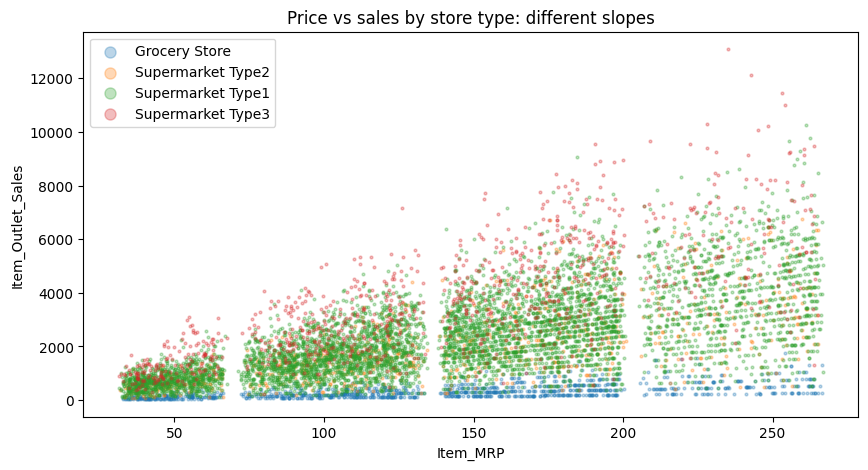


New columns: ['Item_MRP_x_Supermarket Type1', 'Item_MRP_x_Supermarket Type2', 'Item_MRP_x_Supermarket Type3']
Shape after: (14204, 47)


In [ ]:
# EDA STAGE: 7. VARIABLE TRANSFORMATION (7.3 interaction terms)
# CELL 19: Step 7.3 - Item_MRP x each Outlet_Type column
# A plain linear model gives price ONE slope for every store.
# First check: is the price slope really different per store type? (train only)

train_rows = data[data["source"] == "train"]
type_cols = ["Outlet_Type_Supermarket Type1", "Outlet_Type_Supermarket Type2", "Outlet_Type_Supermarket Type3"]

# Which store type is each row? (all three 0 = Grocery, the reference)
store_type = train_rows[type_cols].idxmax(axis=1).str.replace("Outlet_Type_", "")
store_type[train_rows[type_cols].sum(axis=1) == 0] = "Grocery Store"

print("Sales added per 1 unit of MRP, fitted separately for each store type:")
for t in ["Grocery Store", "Supermarket Type2", "Supermarket Type1", "Supermarket Type3"]:
    rows = train_rows[store_type == t]
    slope = np.polyfit(rows["Item_MRP"], rows["Item_Outlet_Sales"], 1)[0]
    print(f"  {t:<18}: {slope:6.2f}")

# Scatter: MRP vs sales, one colour per store type
plt.figure(figsize=(10, 5))
for t in ["Grocery Store", "Supermarket Type2", "Supermarket Type1", "Supermarket Type3"]:
    rows = train_rows[store_type == t]
    plt.scatter(rows["Item_MRP"], rows["Item_Outlet_Sales"], s=4, alpha=0.3, label=t)
plt.xlabel("Item_MRP"); plt.ylabel("Item_Outlet_Sales")
plt.title("Price vs sales by store type: different slopes")
plt.legend(markerscale=4)
plt.show()

# Create the 3 interaction columns
for c in type_cols:
    data["Item_MRP_x_" + c.replace("Outlet_Type_", "")] = data["Item_MRP"] * data[c]

print("\nNew columns:", [c for c in data.columns if c.startswith("Item_MRP_x_")])
print("Shape after:", data.shape)

In [ ]:
# EDA STAGE: 7. VARIABLE TRANSFORMATION (7.4 drop columns + split)
# CELL 20: Step 7.4 - Remove what the model shouldn't see, then split train/test
# Two rules for dropping:
#   Rule 1 - WEAK: small gap / SD (Cell 11) or tiny correlation -> barely moves sales
#   Rule 2 - REDUNDANT: repeats other columns, so it adds nothing whatever its gap
# a) Not features:
# - Item_Identifier: an ID (1,559 values), the model would memorise it, not learn
# - Outlet_Establishment_Year, Outlet_Age: each store has one year -> store IDs carry it
# b) Weak (Rule 1):
# - Item_Weight (corr 0.014), Item_Visibility, Visibility_Ratio, Visibility_log
# - Item_Type 15 columns (gap/SD 0.26)
# - Item_Fat_Content 2 columns (gap/SD 0.04, smallest of all)
# - Item_Category 2 columns (gap/SD 0.13)
# - Item_MRP_Band: 0.965 correlated with Item_MRP, adds nothing beyond it
# c) Redundant (Rule 2): each store has one fixed type/size/tier, so the 9 store-ID
# columns already contain them (Type2 = OUT018, Type3 = OUT027 exactly).
# Keeping them would split coefficients arbitrarily between identical columns.
# The MRP x Outlet_Type interactions STAY: store IDs shift the level, not the price slope.

data = data.drop(columns=["Item_Identifier", "Outlet_Establishment_Year", "Outlet_Age"])

weak_cols = (["Item_Weight", "Item_Visibility", "Item_Visibility_Ratio", "Item_Visibility_log", "Item_MRP_Band"] + [c for c in data.columns if c.startswith(("Item_Type_", "Item_Fat_Content_", "Item_Category_"))])

redundant_cols = ["Outlet_Size", "Outlet_Location_Type", "Outlet_Type_Supermarket Type1", "Outlet_Type_Supermarket Type2", "Outlet_Type_Supermarket Type3"]

drop_cols = weak_cols + redundant_cols
print("Weak columns:", len(weak_cols), "| Redundant columns:", len(redundant_cols), "| Total dropped:", len(drop_cols))

# Split back using the source label
train_df = data[data["source"] == "train"].drop(columns=["source"])
test_df = data[data["source"] == "test"].drop(columns=["source", "Item_Outlet_Sales"])

y_train = train_df["Item_Outlet_Sales"]
X_train_full = train_df.drop(columns=["Item_Outlet_Sales"]) # all columns, for the Step 8 comparison
X_train = X_train_full.drop(columns=drop_cols)  # final feature set
X_test = test_df.drop(columns=drop_cols)

print("X_train_full:", X_train_full.shape)
print("X_train:", X_train.shape, "| y_train:", y_train.shape, "| X_test:", X_test.shape)
print("Same columns in train and test:", list(X_train.columns) == list(X_test.columns))
print("Non-numeric columns:", X_train.select_dtypes(exclude="number").columns.tolist())
print("Blanks in X_train / X_test / y_train:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum(), y_train.isnull().sum())

# Redundancy check: number of independent columns (+1 for the intercept)
# Equal to column count + 1 = no column is a copy of others
rank_full = np.linalg.matrix_rank(np.column_stack([np.ones(len(X_train_full)), X_train_full.values]))
rank_final = np.linalg.matrix_rank(np.column_stack([np.ones(len(X_train)), X_train.values]))
print(f"\nIndependent columns - all columns: {rank_full} of {X_train_full.shape[1] + 1}")
print(f"Independent columns - final set  : {rank_final} of {X_train.shape[1] + 1}")

print(f"\nFinal {X_train.shape[1]} columns:")
for c in X_train.columns:
    print("  ", c)

Weak columns: 24 | Redundant columns: 5 | Total dropped: 29
X_train_full: (8523, 42)
X_train: (8523, 13) | y_train: (8523,) | X_test: (5681, 13)
Same columns in train and test: True
Non-numeric columns: []
Blanks in X_train / X_test / y_train: 0 0 0

Independent columns - all columns: 36 of 43
Independent columns - final set  : 14 of 14

Final 13 columns:
   Item_MRP
   Outlet_Identifier_OUT013
   Outlet_Identifier_OUT017
   Outlet_Identifier_OUT018
   Outlet_Identifier_OUT019
   Outlet_Identifier_OUT027
   Outlet_Identifier_OUT035
   Outlet_Identifier_OUT045
   Outlet_Identifier_OUT046
   Outlet_Identifier_OUT049
   Item_MRP_x_Supermarket Type1
   Item_MRP_x_Supermarket Type2
   Item_MRP_x_Supermarket Type3


In [ ]:
# MODELLING
# CELL 21: Step 8.1 - Baseline and linear regression, 5-fold cross-validation (CV)
# What we're doing: score each model the same way so they can be compared fairly. Then use CV using same 5 folds for every model (random_state=42).Predictions below 0 set to 0.

from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression

cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}   # model name -> mean CV RMSE

def cv_rmse(model, name, X):
    errs = []
    for tr_idx, va_idx in cv.split(X):
        model.fit(X.iloc[tr_idx], y_train.iloc[tr_idx])
        p = np.clip(model.predict(X.iloc[va_idx]), 0, None)
        errs.append(np.sqrt(np.mean((p - y_train.iloc[va_idx].values) ** 2)))
    errs = np.array(errs)
    results[name] = errs.mean()
    print(f"{name:<35}: RMSE {errs.mean():8.2f}  (± {errs.std():.2f})  [{X.shape[1]} cols]")

# Baseline: always predict the average sales.
class MeanBaseline:
    def fit(self, X, y): self.m = y.mean(); return self
    def predict(self, X): return np.full(len(X), self.m)

cv_rmse(MeanBaseline(), "Baseline (mean)", X_train)
cv_rmse(LinearRegression(), "Linear regression", X_train)

Baseline (mean)                    : RMSE  1706.71  (± 32.20)  [13 cols]
Linear regression                  : RMSE  1071.73  (± 33.88)  [13 cols]


In [ ]:
# FINAL MODEL + SUBMISSION
# CELL 22: Step 9.1 - Refit linear regression on all train rows, predict test, write submission
# What we're doing: CV trained on 4/5 of the rows each time. Now refit once on ALL 8,523 train rows, predict the 5,681 test rows, and save the file in the exact format of the sample submission.

from google.colab import files

final_model = LinearRegression()
final_model.fit(X_train, y_train)

pred = final_model.predict(X_test)
print("Negative predictions (set to 0):", (pred < 0).sum())
pred = np.clip(pred, 0, None)

submission = pd.DataFrame({ "Item_Identifier": test_ids["Item_Identifier"].values, "Outlet_Identifier": test_ids["Outlet_Identifier"].values, "Item_Outlet_Sales": pred })

# Checks against the sample submission (loaded in Cell 1)
print("Submission shape:", submission.shape, "| sample:", sample_sub.shape)
print("Columns match sample:", list(submission.columns) == list(sample_sub.columns))
print("Row order matches sample:", (submission["Item_Identifier"].values == sample_sub["Item_Identifier"].values).all() and (submission["Outlet_Identifier"].values == sample_sub["Outlet_Identifier"].values).all())
print("Blanks:", submission.isnull().sum().sum())
print(f"Predictions: mean {pred.mean():.2f}, min {pred.min():.2f}, max {pred.max():.2f}")
print(f"Train sales mean (for comparison): {y_train.mean():.2f}")

submission.to_csv("submission.csv", index=False)
files.download("submission.csv")

Negative predictions (set to 0): 0
Submission shape: (5681, 3) | sample: (5681, 3)
Columns match sample: True
Row order matches sample: True
Blanks: 0
Predictions: mean 2182.26, min 72.96, max 6869.19
Train sales mean (for comparison): 2181.29


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# FINAL MODEL + SUBMISSION
# CELL 23: Step 9.2 - What the final model learned
# What we're doing: read the coefficients.
# - Price slope per store type = Item_MRP coefficient + that type's interaction(Grocery is the reference, so its slope is just the Item_MRP coefficient)
# - Store shifts are vs OUT010 (the reference store)

coefs = pd.Series(final_model.coef_, index=X_train.columns)
print(f"Intercept: {final_model.intercept_:.2f}\n")

base_slope = coefs["Item_MRP"]
print("Sales added per +1 MRP, by store type:")
print(f"  {'Grocery Store':<18}: {base_slope:6.2f}")
for t in ["Supermarket Type1", "Supermarket Type2", "Supermarket Type3"]:
    print(f"  {t:<18}: {base_slope + coefs['Item_MRP_x_' + t]:6.2f}")

print("\nStore shift vs OUT010:")
print(coefs[[c for c in coefs.index if c.startswith("Outlet_Identifier_")]].round(2).to_string())

Intercept: -8.78

Sales added per +1 MRP, by store type:
  Grocery Store     :   2.47
  Supermarket Type1 :  16.60
  Supermarket Type2 :  14.62
  Supermarket Type3 :  25.35

Store shift vs OUT010:
Outlet_Identifier_OUT013    -39.84
Outlet_Identifier_OUT017     35.12
Outlet_Identifier_OUT018    -66.93
Outlet_Identifier_OUT019      3.43
Outlet_Identifier_OUT027    158.92
Outlet_Identifier_OUT035     71.84
Outlet_Identifier_OUT045   -138.55
Outlet_Identifier_OUT046    -71.47
Outlet_Identifier_OUT049     28.25
